In [ ]:
from google.colab import userdata
from googleapiclient.discovery import build
import pandas as pd

In [ ]:
API_KEY = userdata.get("YT_API_KEY")

youtube = build(
    "youtube",
    "v3",
    developerKey=API_KEY
)

Videos Used:  
https://www.youtube.com/watch?v=qAe8oGKiRbc  
https://www.youtube.com/watch?v=_FcHPrRY5zg  
https://www.youtube.com/watch?v=Zr5a1C5UjiA  
https://www.youtube.com/watch?v=djOlA8MOFSo  
https://www.youtube.com/watch?v=Mqn0yLrxjpU  
https://www.youtube.com/watch?v=9H8yqvCY4vk  
https://www.youtube.com/watch?v=AuMV91myoAc  

# Scraping Comments

In [ ]:
video_ids = [
    "qAe8oGKiRbc",
    "_FcHPrRY5zg",
    "Zr5a1C5UjiA",
    "djOlA8MOFSo",
    "Mqn0yLrxjpU",
    "9H8yqvCY4vk",
    "AuMV91myoAc",
]

comments_per_video = 500

Jumlah komen per video di limit agar tidak terlalu bias kepada satu video.

In [ ]:
all_comments = []

for video_id in video_ids:

    print(f"Scraping video: {video_id}")

    request = youtube.commentThreads().list(
        part="snippet",
        videoId=video_id,
        maxResults=100
    )

    comments_count = 0

    while request and comments_count < comments_per_video:

        response = request.execute()

        for item in response["items"]:

            comment = item["snippet"]["topLevelComment"]["snippet"]

            all_comments.append({
                "video_id": video_id,
                "author": comment["authorDisplayName"],
                "comment": comment["textDisplay"],
                "likes": comment["likeCount"],
                "published": comment["publishedAt"]
            })

            comments_count += 1

            if comments_count >= comments_per_video:
                break

        request = youtube.commentThreads().list_next(
            request,
            response
        )

    print(f"Collected {comments_count} comments")

df = pd.DataFrame(all_comments)

print(f"\nTotal comments: {len(df)}")
df.head()

Scraping video: qAe8oGKiRbc
Collected 362 comments
Scraping video: _FcHPrRY5zg
Collected 500 comments
Scraping video: Zr5a1C5UjiA
Collected 26 comments
Scraping video: djOlA8MOFSo
Collected 17 comments
Scraping video: Mqn0yLrxjpU
Collected 12 comments
Scraping video: 9H8yqvCY4vk
Collected 234 comments
Scraping video: AuMV91myoAc
Collected 18 comments

Total comments: 1169


,video_id,author,comment,likes,published
0,qAe8oGKiRbc,@edisantosa985,Menurut saya AI itu pembantu manusia yang pali...,0,2026-01-17T02:47:04Z
1,qAe8oGKiRbc,@edisantosa985,Yang lebih bahaya dari AI bukankah karena bisa...,0,2026-01-17T02:38:04Z
2,qAe8oGKiRbc,@komangagus46,suatu perkembangan antar ber energi dengan kea...,0,2025-09-03T03:50:06Z
3,qAe8oGKiRbc,@HSusanto-n7j,Secanggih apapun sistem...itu masih bodoh dan ...,0,2025-08-13T08:09:52Z
4,qAe8oGKiRbc,@maswienwae__4437,Yg paling dikawatirkan itu jika suatu saat rob...,0,2025-06-07T23:03:24Z


# A. Preprocessing & Text Representation

In [ ]:
!pip install Sastrawi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 1.7 MB/s eta 0:00:00


In [ ]:
import re
import string
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
import nltk

In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

## Preprocessing

In [ ]:
def cleansing(text):
    # lower case text
    text = str(text).lower()

    # hapus url
    text = re.sub(r'http\S+|www\S+', '', text)

    # hapus angka
    text = re.sub(r'\d+', '', text)

    # hapus tanda baca
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    # hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    return text

Komen di lower-case, angka & tanda baca di hapus, spasi lebih dihapus dan url dihapus.

In [ ]:
def tokenization(text):
    return word_tokenize(text)

stop_words = set(
    stopwords.words('indonesian')
)

def filtering(tokens):
    filtered = [word for word in tokens if word not in stop_words and len(word) > 2]
    return filtered

Setelah itu, dilakukan tokenization dan filtering.

In [ ]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

def stemming(tokens):
    stemmed = [stemmer.stem(word) for word in tokens]
    return stemmed

Kata-kata dalam komen di stemming.

In [ ]:
df["clean_text"] = df["comment"].apply(cleansing)

df["tokens"] = df["clean_text"].apply(tokenization)

df["filtered"] = df["tokens"].apply(filtering)

df["stemmed"] = df["filtered"].apply(stemming)

df.head()

,video_id,author,comment,likes,published,clean_text,tokens,filtered,stemmed
0,qAe8oGKiRbc,@edisantosa985,Menurut saya AI itu pembantu manusia yang pali...,0,2026-01-17T02:47:04Z,menurut saya ai itu pembantu manusia yang pali...,"[menurut, saya, ai, itu, pembantu, manusia, ya...","[pembantu, manusia, hebat, penghancur, manusia...","[bantu, manusia, hebat, hancur, manusia, hebat..."
1,qAe8oGKiRbc,@edisantosa985,Yang lebih bahaya dari AI bukankah karena bisa...,0,2026-01-17T02:38:04Z,yang lebih bahaya dari ai bukankah karena bisa...,"[yang, lebih, bahaya, dari, ai, bukankah, kare...","[bahaya, mengganti, manusia, manusia, berhenti...","[bahaya, ganti, manusia, manusia, henti, manusia]"
2,qAe8oGKiRbc,@komangagus46,suatu perkembangan antar ber energi dengan kea...,0,2025-09-03T03:50:06Z,suatu perkembangan antar ber energi dengan kea...,"[suatu, perkembangan, antar, ber, energi, deng...","[perkembangan, ber, energi, fisik, sistem, men...","[kembang, ber, energi, fisik, sistem, mengunak..."
3,qAe8oGKiRbc,@HSusanto-n7j,Secanggih apapun sistem...itu masih bodoh dan ...,0,2025-08-13T08:09:52Z,secanggih apapun sistemitu masih bodoh dan pun...,"[secanggih, apapun, sistemitu, masih, bodoh, d...","[secanggih, apapun, sistemitu, bodoh, kelemaha...","[canggih, apa, sistemitu, bodoh, kelemahandi, ..."
4,qAe8oGKiRbc,@maswienwae__4437,Yg paling dikawatirkan itu jika suatu saat rob...,0,2025-06-07T23:03:24Z,yg paling dikawatirkan itu jika suatu saat rob...,"[yg, paling, dikawatirkan, itu, jika, suatu, s...","[dikawatirkan, robot, mengalami, stres, level,...","[dikawatirkan, robot, alami, stres, level, cer..."


In [ ]:
# saving to csv so can load without scrapping again
df.to_csv(
    "comments_yt.csv",
    index=False,
    encoding="utf-8-sig"
)

In [ ]:
df = pd.read_csv("comments_yt.csv")
df.head()

,video_id,author,comment,likes,published,clean_text,tokens,filtered,stemmed
0,qAe8oGKiRbc,@edisantosa985,Menurut saya AI itu pembantu manusia yang pali...,0,2026-01-17T02:47:04Z,menurut saya ai itu pembantu manusia yang pali...,"['menurut', 'saya', 'ai', 'itu', 'pembantu', '...","['pembantu', 'manusia', 'hebat', 'penghancur',...","['bantu', 'manusia', 'hebat', 'hancur', 'manus..."
1,qAe8oGKiRbc,@edisantosa985,Yang lebih bahaya dari AI bukankah karena bisa...,0,2026-01-17T02:38:04Z,yang lebih bahaya dari ai bukankah karena bisa...,"['yang', 'lebih', 'bahaya', 'dari', 'ai', 'buk...","['bahaya', 'mengganti', 'manusia', 'manusia', ...","['bahaya', 'ganti', 'manusia', 'manusia', 'hen..."
2,qAe8oGKiRbc,@komangagus46,suatu perkembangan antar ber energi dengan kea...,0,2025-09-03T03:50:06Z,suatu perkembangan antar ber energi dengan kea...,"['suatu', 'perkembangan', 'antar', 'ber', 'ene...","['perkembangan', 'ber', 'energi', 'fisik', 'si...","['kembang', 'ber', 'energi', 'fisik', 'sistem'..."
3,qAe8oGKiRbc,@HSusanto-n7j,Secanggih apapun sistem...itu masih bodoh dan ...,0,2025-08-13T08:09:52Z,secanggih apapun sistemitu masih bodoh dan pun...,"['secanggih', 'apapun', 'sistemitu', 'masih', ...","['secanggih', 'apapun', 'sistemitu', 'bodoh', ...","['canggih', 'apa', 'sistemitu', 'bodoh', 'kele..."
4,qAe8oGKiRbc,@maswienwae__4437,Yg paling dikawatirkan itu jika suatu saat rob...,0,2025-06-07T23:03:24Z,yg paling dikawatirkan itu jika suatu saat rob...,"['yg', 'paling', 'dikawatirkan', 'itu', 'jika'...","['dikawatirkan', 'robot', 'mengalami', 'stres'...","['dikawatirkan', 'robot', 'alami', 'stres', 'l..."


In [ ]:
import ast

df['stemmed'] = df['stemmed'].apply(ast.literal_eval)

extra_stopwords = [
    'nya','aja','gak','kalo','bang','','yg','ya', 'manusia', 'sih', 'the', 'href'
]

df['stemmed'] = df['stemmed'].apply(
    lambda x: [w for w in x if w not in extra_stopwords]
)

df[['stemmed']].head()

,stemmed
0,"[bantu, hebat, hancur, hebat, wait, and, see]"
1,"[bahaya, ganti, henti]"
2,"[kembang, ber, energi, fisik, sistem, mengunak..."
3,"[canggih, apa, sistemitu, bodoh, kelemahandi, ..."
4,"[dikawatirkan, robot, alami, stres, level, cer..."


Tambahan filtering ke kata-kata yang sudah di stemming.

In [ ]:
df['final_text'] = df['stemmed'].apply(lambda x: ' '.join(x))
df.head()

,video_id,author,comment,likes,published,clean_text,tokens,filtered,stemmed,final_text
0,qAe8oGKiRbc,@edisantosa985,Menurut saya AI itu pembantu manusia yang pali...,0,2026-01-17T02:47:04Z,menurut saya ai itu pembantu manusia yang pali...,"['menurut', 'saya', 'ai', 'itu', 'pembantu', '...","['pembantu', 'manusia', 'hebat', 'penghancur',...","[bantu, hebat, hancur, hebat, wait, and, see]",bantu hebat hancur hebat wait and see
1,qAe8oGKiRbc,@edisantosa985,Yang lebih bahaya dari AI bukankah karena bisa...,0,2026-01-17T02:38:04Z,yang lebih bahaya dari ai bukankah karena bisa...,"['yang', 'lebih', 'bahaya', 'dari', 'ai', 'buk...","['bahaya', 'mengganti', 'manusia', 'manusia', ...","[bahaya, ganti, henti]",bahaya ganti henti
2,qAe8oGKiRbc,@komangagus46,suatu perkembangan antar ber energi dengan kea...,0,2025-09-03T03:50:06Z,suatu perkembangan antar ber energi dengan kea...,"['suatu', 'perkembangan', 'antar', 'ber', 'ene...","['perkembangan', 'ber', 'energi', 'fisik', 'si...","[kembang, ber, energi, fisik, sistem, mengunak...",kembang ber energi fisik sistem mengunakan chips
3,qAe8oGKiRbc,@HSusanto-n7j,Secanggih apapun sistem...itu masih bodoh dan ...,0,2025-08-13T08:09:52Z,secanggih apapun sistemitu masih bodoh dan pun...,"['secanggih', 'apapun', 'sistemitu', 'masih', ...","['secanggih', 'apapun', 'sistemitu', 'bodoh', ...","[canggih, apa, sistemitu, bodoh, kelemahandi, ...",canggih apa sistemitu bodoh kelemahandi msh bt...
4,qAe8oGKiRbc,@maswienwae__4437,Yg paling dikawatirkan itu jika suatu saat rob...,0,2025-06-07T23:03:24Z,yg paling dikawatirkan itu jika suatu saat rob...,"['yg', 'paling', 'dikawatirkan', 'itu', 'jika'...","['dikawatirkan', 'robot', 'mengalami', 'stres'...","[dikawatirkan, robot, alami, stres, level, cer...",dikawatirkan robot alami stres level cerdas ti...


Kata-kata digabung menjadi satu string.

## Text Representation

### TF-IDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000
)

X_tfidf = tfidf.fit_transform(df['final_text'])

print(X_tfidf.shape)

(1169, 4415)


Teknik text representation pertama yang digunakan adalah TF-IDF atau Term Frequency Inverse Document Frequency. TF-IDF mengubah kata menjadi angka berdasarkan frekuensi muncul kata dalam dokumen dan seberapa langka kata itu ada di semua dokumen. Terdapat 4415 fitur atau kata-kata yang unik setelah preprocessing dalam 1169 komen tersebut.

### Word Embeddings

In [ ]:
!pip install gensim

In [ ]:
from gensim.models import Word2Vec
import numpy as np

tokenized = df['stemmed']

# train model
w2v_model = Word2Vec(
    sentences = tokenized,
    vector_size = 100,
    window = 5,
    min_count = 2,
    workers = 4
)

In [ ]:
# convert each document into average vector
def document_vector(doc):
    words = doc.split()

    vectors = [w2v_model.wv[word] for word in words if word in w2v_model.wv]

    if len(vectors) == 0:
        return np.zeros(100)

    return np.mean(vectors, axis=0)

X_word2vec = np.array([document_vector(doc) for doc in df['final_text']])

print(X_word2vec.shape)

(1169, 100)


Word embeddings mencoba mempelajari arti dari kata-kata tersebut dan bukan hanya menghitung kepentingan kata-katanya. Ia akan melihat kata-kata tentangganya untuk melihat relasi antara kata itu dengan tetangganya.

# B. Clustering

## TF-IDF

K = 2, Silhouette = 0.0068
K = 3, Silhouette = 0.0100
K = 4, Silhouette = 0.0103
K = 5, Silhouette = 0.0119
K = 6, Silhouette = 0.0149
K = 7, Silhouette = 0.0162
K = 8, Silhouette = 0.0172
K = 9, Silhouette = 0.0174
K = 10, Silhouette = 0.0199


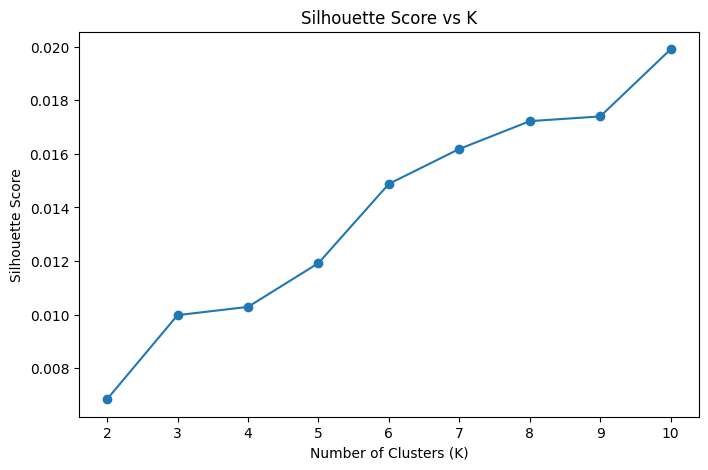

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

k_values = range(2,11)
silhouette_scores = []

for k in k_values:

    kmeans = KMeans(
        n_clusters = k,
        random_state = 21,
        n_init = 10
    )

    labels = kmeans.fit_predict(X_tfidf)

    score = silhouette_score(
        X_tfidf,
        labels
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette = {score:.4f}")

plt.figure(figsize=(8,5))
plt.plot(k_values, silhouette_scores, marker = 'o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")
plt.show()

In [ ]:
best_k_tfidf = k_values[silhouette_scores.index(max(silhouette_scores))]
print("Best K:", best_k_tfidf)

Best K: 10


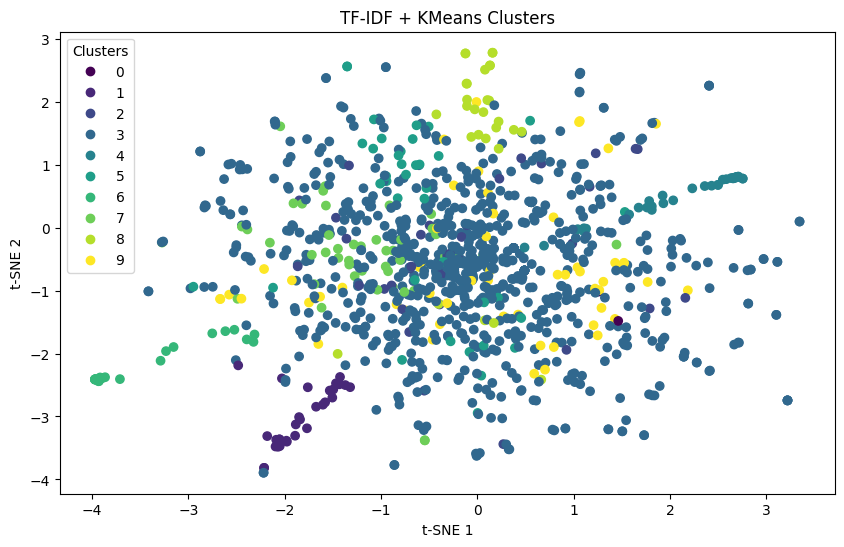

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

kmeans_tfidf = KMeans(
    n_clusters = 10,
    random_state = 21
)

labels_tfidf = kmeans_tfidf.fit_predict(X_tfidf)

tsne = TSNE(
    n_components = 2,
    random_state = 21,
    perplexity = 30
)

X_tfidf_2d = tsne.fit_transform(X_tfidf.toarray())

# Plot
plt.figure(figsize=(10,6))

scatter = plt.scatter(
    X_tfidf_2d[:,0],
    X_tfidf_2d[:,1],
    c=labels_tfidf
)

plt.legend(
    *scatter.legend_elements(),
    title="Clusters"
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("TF-IDF + KMeans Clusters")

plt.show()

Dari silhoutte score, jumlah K yang paling bagus adalah karena mempunyai silhoutte score tertinggi. Akan tetapi, silhoutte score untuk setiap K sangat rendah. Artinya, TF-IDF kurang bisa mengelompokan komen-komennya. Dapat dilihat dari plot bahwa untuk TF-IDF, pengelompokan komen-komen susah dilakukan.

## Word Embeddings

K=2, Silhouette=0.3545
K=3, Silhouette=0.2842
K=4, Silhouette=0.2160
K=5, Silhouette=0.1880
K=6, Silhouette=0.1518
K=7, Silhouette=0.1380
K=8, Silhouette=0.1309
K=9, Silhouette=0.1451
K=10, Silhouette=0.1322


Text(0.5, 1.0, 'Silhouette Score vs K')

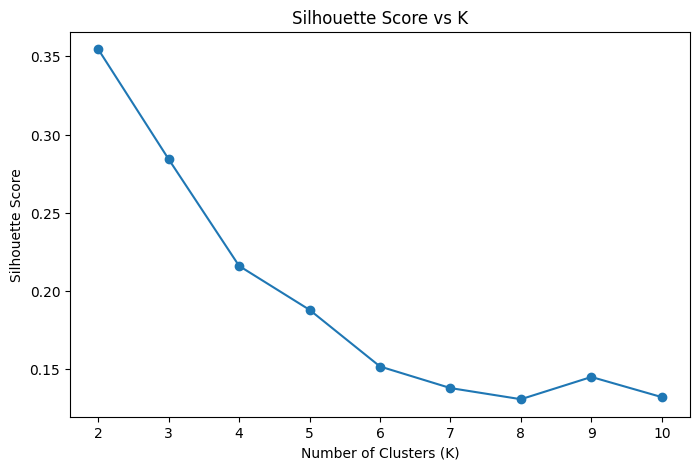

In [ ]:
silhouette_scores_w2v = []

for k in range(2,11):

    kmeans = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )

    labels = kmeans.fit_predict(X_word2vec)

    score = silhouette_score(
        X_word2vec,
        labels
    )

    silhouette_scores_w2v.append(score)
    print(f"K={k}, Silhouette={score:.4f}")

plt.figure(figsize=(8,5))
plt.plot(k_values, silhouette_scores_w2v, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs K")

In [ ]:
best_k_w2v = k_values[silhouette_scores_w2v.index(max(silhouette_scores_w2v))]
print("Best K:", best_k_w2v)

Best K: 2


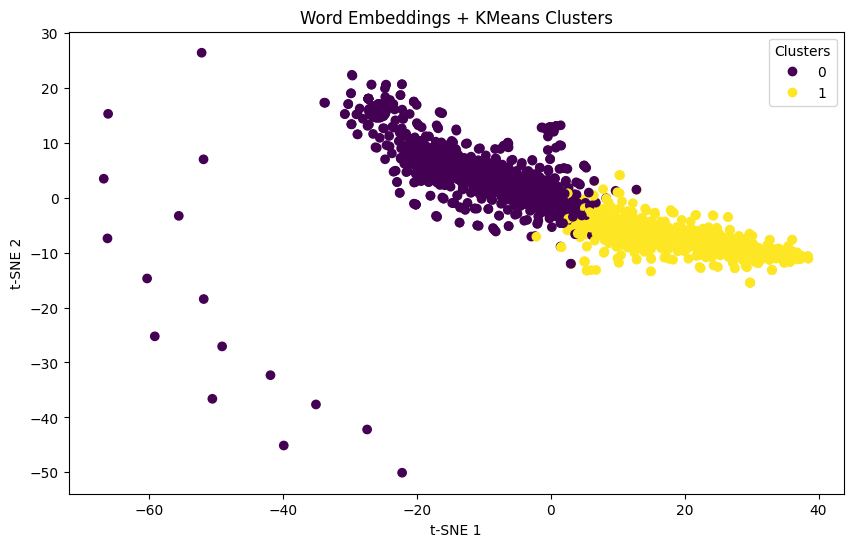

In [ ]:
kmeans_w2v = KMeans(
    n_clusters = 2,
    random_state = 21
)

labels_w2v = kmeans_w2v.fit_predict(X_word2vec)

tsne = TSNE(
    n_components = 2,
    random_state = 21,
    perplexity = 30
)

X_w2v_2d = tsne.fit_transform(X_word2vec)

# Plot
plt.figure(figsize=(10,6))

scatter = plt.scatter(
    X_w2v_2d[:,0],
    X_w2v_2d[:,1],
    c = labels_w2v
)

plt.legend(
    *scatter.legend_elements(),
    title="Clusters"
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Word Embeddings + KMeans Clusters")

plt.show()

Dari silhoutte score, nilai K terbaik adalah 2 karena mempunyai silhoutte score tertinggi. Jika dibanginkan dengan TF-IDF, word embeddings lebih bisa mengelompokan komen-komen berdasarkan kemiripannya. Dapat dilihat dari silhoutte score untuk setiap k lebih tinggi daripada silhoutte score TF-IDF. Dari plot, dapat dilihat bahwa pengelompokan lebih bagus daripada TF-IDF. Masih ada yang overlap antara cluster.

# C. Persona Analysis

Persona analisis dilkukan dua kali: satu menggunakan best k dari word embeddings, yaitu 2, dan satu lagi menggunakan 3 kluster untuk melihat apakah penambahan kluster dapat membedakan komen-komen lebih baik. Berikut adalah hasil untuk 2 kluster.

In [ ]:
kmeans_final = KMeans(
    n_clusters = 2,
    random_state = 21,
    n_init = 10
)

df['cluster_w2v'] = kmeans_final.fit_predict(X_word2vec)

In [ ]:
from collections import Counter

for cluster in sorted(df['cluster_w2v'].unique()):

    text = df[df['cluster_w2v'] == cluster]['stemmed']

    words = []

    for tokens in text:
        words.extend(tokens)

    word_freq = Counter(words)

    print("\n")
    print(f"Cluster {cluster}")
    print(word_freq.most_common(15))



Cluster 0
[('banget', 30), ('suara', 28), ('bahas', 27), ('maudy', 27), ('pake', 20), ('orang', 20), ('ayunda', 20), ('video', 19), ('tau', 16), ('ancam', 16), ('bikin', 16), ('pakai', 16), ('kayak', 16), ('data', 15), ('sadar', 15)]


Cluster 1
[('ajar', 133), ('ganti', 131), ('kerja', 124), ('bantu', 98), ('robot', 96), ('teknologi', 96), ('pikir', 95), ('manfaat', 71), ('cepat', 67), ('mudah', 61), ('cerdas', 59), ('positif', 59), ('negatif', 58), ('mampu', 57), ('cari', 56)]


Dari hasil clustering, dapat dilihat dua kelompok. Kelompok 1 atau cluster 0 kelebihan berbicara tentang diskusi dan perasaan penonton mengenai videonya. Dapat dilihat nama-nama orang seperti Maudy dan Ayunda yang mendukung kesimpulan ini.  

Sedangkan, kelompok 2 atau cluster 1 kelebihan berbicara mengenai AI. Dapat dilihat kata-kata seperti teknologi dan robot yang mendukung klaim ini. Selain itu, dapat dilihat kata-kata seperti ajar, bantu, manfaat, dan lain-lainnya yang mungkin membicarakan tentang dampak Ai terhadap pendidikan. Terdapat juga kata-kata negatif yang mungkin membicarakan tentang kekurangan dari AI.  

Sebagai kesimpulan, penggunaan 2 cluster dapat mengelompokan komen-komen tetapi kelompok tersebut hanya antara diskusi general tentang video dan dampak AI dalam pendidikan.  

Selanjutnya, clustering dilakukan menggunakan tiga cluster.

In [ ]:
kmeans_final = KMeans(
    n_clusters = 3,
    random_state = 21,
    n_init = 10
)

df['cluster_w2v'] = kmeans_final.fit_predict(X_word2vec)

In [ ]:
from collections import Counter

for cluster in sorted(df['cluster_w2v'].unique()):

    text = df[df['cluster_w2v'] == cluster]['stemmed']

    words = []

    for tokens in text:
        words.extend(tokens)

    word_freq = Counter(words)

    print("\n")
    print(f"Cluster {cluster}")
    print(word_freq.most_common(15))



Cluster 0
[('banget', 13), ('and', 11), ('nonton', 9), ('maudy', 9), ('pulauwin', 9), ('mas', 8), ('human', 8), ('suara', 8), ('gue', 8), ('like', 7), ('bahas', 7), ('nih', 7), ('not', 7), ('one', 7), ('min', 7)]


Cluster 1
[('robot', 59), ('sadar', 47), ('kerja', 46), ('orang', 45), ('ajar', 42), ('teknologi', 40), ('kembang', 38), ('pakai', 35), ('bikin', 35), ('suara', 35), ('dunia', 34), ('salah', 34), ('milik', 33), ('bahas', 33), ('cipta', 33)]


Cluster 2
[('ganti', 108), ('ajar', 101), ('kerja', 89), ('bantu', 84), ('pikir', 81), ('manfaat', 64), ('teknologi', 61), ('positif', 57), ('negatif', 56), ('cepat', 55), ('siswa', 54), ('dampak', 53), ('terampil', 51), ('mudah', 50), ('robot', 49)]


Jika dibandingakn dengan dua kluster, tiga kluster dapat mengelompokan komen-komennya dengan lebih baik. Dapat dilihat untuk kelompok pertama atau Cluster 0 lebih membicarakan tentang reaksi video dan interaksi dengan videonya. Kata-kata seperti Maudy, Pulauwin, mas, dan nonton mendukung klaim ini. Terdapat juga kata-kata bahasa inggris yang mungkin campur dengan komen-komen bahasa indonesia.

Untuk kelompok 2 atau Cluster 1, komen-komen lebih membicarakan tentang teknologi AI dan penggunaannya di dunia nyata. Kata-kata seperti robot, teknologi, dunia, cipta, dan kembang mendukung klaim ini. Kelompok ini lebih mendiskusikan pengembangan AI dan dampaknya untuk dunia nyata.

Untuk kelompok 3 atau Cluster 2, komen-komen lebih membicarakan tentang dampak AI mengenai pendidikan. Dapat dilihat bahwa terdapat kata-kata seperti bantu, ajar, kerja, manfaat, dan siswa yang mendukung klaim ini. Dapat juga dilihat kata-kata seperti positif dan negatif yang mungkin membicarakan tentang perasaan mereka tentang AI dalam pendidikan. Artinya, ada yang merasa bahwa AI dapat membantu dan ada yang merasa bahwa AI kurang bisa dan berdampak negatif.

Untuk menyimpulkan, tiga kluster lebih cocok karena dapat mengelompokan lebih baik daripada dua kluster saja. Kelompok yang hanya bereaksi tentang video dapat di filter dari kelompok yang membicarakan tentang AI. Kelompok tersebut dipisah lagi menjadi kelompok yang membicarakan tentang pengembangan AI dan dampak AI dalam pendidikan.

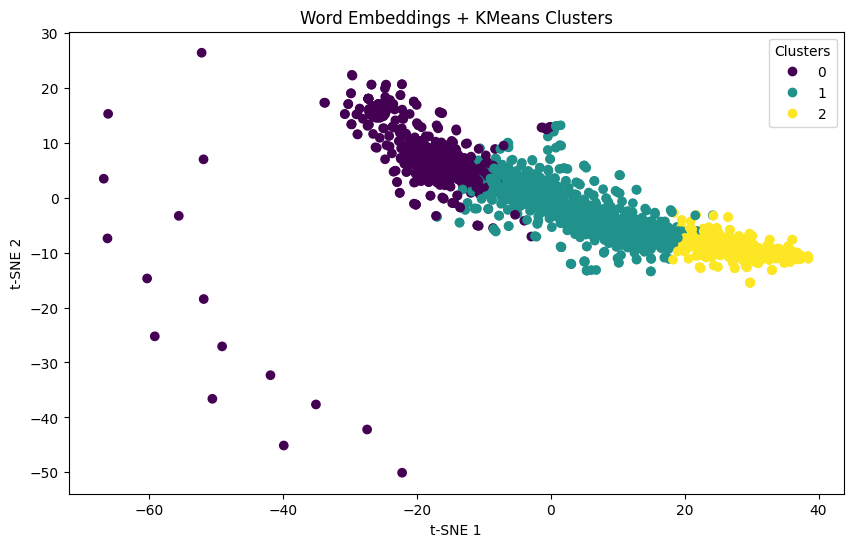

In [ ]:
kmeans_w2v = KMeans(
    n_clusters = 3,
    random_state = 21
)

labels_w2v = kmeans_w2v.fit_predict(X_word2vec)

tsne = TSNE(
    n_components = 2,
    random_state = 21,
    perplexity = 30
)

X_w2v_2d = tsne.fit_transform(X_word2vec)

# Plot
plt.figure(figsize=(10,6))

scatter = plt.scatter(
    X_w2v_2d[:,0],
    X_w2v_2d[:,1],
    c = labels_w2v
)

plt.legend(
    *scatter.legend_elements(),
    title="Clusters"
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Word Embeddings + KMeans Clusters")

plt.show()

Dapat dilihat dari plot bahwa pengelompokan masih bagus jika dilakukan menggunakan tiga kluster dan lebih bermanfaat karena mengandung informasi lebih banyak.

# D. Topic Extraction &  E. Persona Analysis

LDA atau Latent Dirichlet Allocation adalah sebuah metode topic extraction yang dapat digunakan untuk mencari topik-topik yang tersembunyi dari sebuah teks. Pertama, jumlah topic ditentukan terlebih dahulu. Setelah itu, kata-kata akan dibagi ke topik-topik secara random. LDA akan mengecek di dalam dokumen tertentu topic mana yang paling banyak dan secara keseluruhan kata-kata apa yang muncul secara bersama. Proses ini akan diulang-ulang dan akan disesuaikan topicnya.

LDA dilakukan dua kali, satu menggunakan 2 topik komponen dan satu menggunakan 3 topik komponen. Tujuannya untuk melihat jumlah topik yang lebih cocok. 2 digunakan berdasarkan nilai K paling bagus dari word embeddings.

In [ ]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    max_features = 1000
)

X = vectorizer.fit_transform(df['final_text'])

lda = LatentDirichletAllocation(
    n_components = 2,
    random_state = 21
)

lda.fit(X)

LatentDirichletAllocation(n_components=2, random_state=21)

In [ ]:
words = vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda.components_):

    top_words = [words[i] for i in topic.argsort()[-10:]]

    print(f"Topic {topic_idx+1}:")
    print(top_words)

Topic 1:
['bahas', 'suara', 'cipta', 'bikin', 'teknologi', 'orang', 'dunia', 'pakai', 'sadar', 'robot']
Topic 2:
['cari', 'mudah', 'cerdas', 'cepat', 'manfaat', 'pikir', 'bantu', 'kerja', 'ajar', 'ganti']


Dari hasil, topik satu lebih berbicara mengenai teknologi AI secara keseluruhan. Kelompok ini mendiskusikan penggunaan teknologi AI secara keseluruhan yang dapat dilihat dari kata-kata seperti bahas, teknologi, dunia, dan orang.

Topik 2 lebih membicarakan tentang manfaat penggunaan AI dalam pendidikan. Dapat dilihat kata-kata seperti cerdas, cepat, mudah, bantu, dan kerja yang mendukung klaim ini. Kelompok ini merasakan bahwa AI dapat membantu memudahkan pekerjaan-pekerjaan serta kecerdasaannya dapat bermanfaat dalam pendidikan.

In [ ]:
lda = LatentDirichletAllocation(
    n_components = 3,
    random_state = 21
)

lda.fit(X)

words = vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda.components_):

    top_words = [words[i] for i in topic.argsort()[-10:]]

    print(f"Topic {topic_idx+1}:")
    print(top_words)

Topic 1:
['maudy', 'banget', 'cipta', 'bahaya', 'dunia', 'salah', 'teknologi', 'suara', 'pakai', 'robot']
Topic 2:
['positif', 'cari', 'mudah', 'cepat', 'manfaat', 'kerja', 'pikir', 'bantu', 'ajar', 'ganti']
Topic 3:
['ajar', 'otak', 'batas', 'film', 'indonesia', 'bikin', 'kembang', 'sadar', 'orang', 'bahas']


Topik satu membicarakan tentang kekhawatiran dan bahaya yang dapat terjadi ketika menggunakan AI dalam pendidikan. Dapat dilihat kata-kata seperti bahaya, salah, teknologi, dan dunia yang mendukung klaim ini. Terdapat juga kata-kata noise seperti Maudy yang mungkin adalah seorang pembicara. Kelompok ini berpendapat bahwa pengguaan teknologi AI dapat berbahaya jika di salah gunakan dalam dunia pendidikan.

Topik kedua membicarakan tentang kelebihan penggunaan AI dalam pendidikan. Dapat dilihat kata-kata seperti mudah, positif, kerja, bantu, dan manfaat yang mendukung klaim ini. Kelompok ini berpendapat bahwa pengguaan AI dana membantu menyelesaikan pekerjaan, membuat pekerjaan lebih cepat dan mudah, serta membantu mengajar.

Topik ketiga membicarakan tentang otak manusia dan pembembangan AI di Indonesia. Kata-kata seperti kembang, batas, otak, orang, dan Indonesia mendukung ini. Kelompok ini lebih berbicara tentang ilmu manusia dengan keterbatasannya dan pengembangan lebih lanjut AI.

Jika dibandingkan dengan dua topik, tiga topik dapat lebih menangkap pendapat-pendapat orang yang beda-beda. Dapat dilihat bahwa ada yang berpendapat negatif, positif, dan ada yang mendiskusikan tentang pengembangan AI kedepannya.

Jika dibanginkan dengan hasil dari KMeans clustering, LDA jauh lebih bagus digunakan karena dapat lebih menangkap pendapat-pendapat orang lebih baik daripada KMeans. Jika dilihat dalam clustering, masih terdapat topik-topik yang tidak bermanfaat, seperti reaksi orang terhadap video, untuk tujuan analisis ini. Sedangkan, LDA dapat menghasilkan topik-topik yang bermanfaat karena seiring dengan tujuan analisis ini yaitu dampak AI dalam dunia pendidikan.